In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("heart_disease_large_practice.xlsx")

df.head()

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,max_heart_rate,exercise_angina,smoker,bmi,heart_disease
0,465,40,Male,asymptomatic,128.0,194.0,0,141.0,No,No,23.3,0
1,621,55,female,asymptomatic,120.0,287.0,0,187.0,Yes,No,30.0,0
2,163,48,Female,non-anginal,152.0,155.0,0,151.0,No,No,24.0,0
3,314,56,F,NON-ANGINAL,121.0,220.0,0,136.0,Yes,No,28.2,0
4,593,69,Male,typical angina,150.0,210.0,0,129.0,No,No,28.4,1


In [2]:
print(df.shape)
df.info()
df.head()

(1025, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           1025 non-null   int64  
 1   age                  1025 non-null   int64  
 2   sex                  1025 non-null   str    
 3   chest_pain_type      1025 non-null   str    
 4   resting_bp           993 non-null    float64
 5   cholesterol          982 non-null    float64
 6   fasting_blood_sugar  1025 non-null   int64  
 7   max_heart_rate       992 non-null    float64
 8   exercise_angina      1025 non-null   str    
 9   smoker               1025 non-null   str    
 10  bmi                  970 non-null    float64
 11  heart_disease        1025 non-null   int64  
dtypes: float64(4), int64(4), str(4)
memory usage: 118.0 KB


,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,max_heart_rate,exercise_angina,smoker,bmi,heart_disease
0,465,40,Male,asymptomatic,128.0,194.0,0,141.0,No,No,23.3,0
1,621,55,female,asymptomatic,120.0,287.0,0,187.0,Yes,No,30.0,0
2,163,48,Female,non-anginal,152.0,155.0,0,151.0,No,No,24.0,0
3,314,56,F,NON-ANGINAL,121.0,220.0,0,136.0,Yes,No,28.2,0
4,593,69,Male,typical angina,150.0,210.0,0,129.0,No,No,28.4,1


In [3]:
df.describe()

,patient_id,age,resting_bp,cholesterol,fasting_blood_sugar,max_heart_rate,bmi,heart_disease
count,1025.000000,1025.000000,993.000000,982.000000,1025.000000,992.000000,970.000000,1025.000000
mean,513.000000,54.935610,130.021148,234.385947,0.114146,157.423387,27.290000,0.124878
std,296.036315,42.954643,19.398115,52.373480,0.318144,21.371779,4.934133,0.330742
min,1.000000,-1.000000,0.000000,0.000000,0.000000,20.000000,2.100000,0.000000
25%,257.000000,47.000000,119.000000,203.000000,0.000000,146.000000,24.300000,0.000000
50%,513.000000,53.000000,130.000000,237.000000,0.000000,157.000000,27.100000,0.000000
75%,769.000000,59.000000,142.000000,268.750000,0.000000,170.250000,30.000000,0.000000
max,1025.000000,999.000000,300.000000,382.000000,1.000000,300.000000,98.500000,1.000000


In [4]:
df.isnull().sum()

patient_id              0
age                     0
sex                     0
chest_pain_type         0
resting_bp             32
cholesterol            43
fasting_blood_sugar     0
max_heart_rate         33
exercise_angina         0
smoker                  0
bmi                    55
heart_disease           0
dtype: int64

In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

patient_id             0.000000
age                    0.000000
sex                    0.000000
chest_pain_type        0.000000
resting_bp             3.121951
cholesterol            4.195122
fasting_blood_sugar    0.000000
max_heart_rate         3.219512
exercise_angina        0.000000
smoker                 0.000000
bmi                    5.365854
heart_disease          0.000000
dtype: float64


In [6]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [7]:
duplicates = df.duplicated(
    subset=df.columns.drop("patient_id")
)

print("Duplicate patient records:", duplicates.sum())

Duplicate patient records: 25


In [8]:
print(df["sex"].value_counts(dropna=False))

print(df["chest_pain_type"].value_counts(dropna=False))

sex
Male       599
Female     257
MALE        39
 Male       25
male        21
female      20
Female      19
M           17
F           15
FEMALE      13
Name: count, dtype: int64
chest_pain_type
asymptomatic        415
non-anginal         261
atypical angina     197
typical angina      105
Asymptomatic          8
NON-ANGINAL           7
ASYMPTOMATIC          5
non-anginal           5
Non-Anginal           4
Atypical Angina       4
asymptomatic          4
Typical Angina        3
ATYPICAL ANGINA       3
atypical angina       3
typical angina        1
Name: count, dtype: int64


In [9]:
df.columns = df.columns.str.strip().str.lower()

In [10]:
# Replace blank strings and whitespace-only strings
df = df.replace(r"^\s*$", np.nan, regex=True)

# Replace text markers for missing values
df = df.replace(
    r"(?i)^\s*(NA|N/A)\s*$",
    np.nan,
    regex=True
)

In [11]:
df["sex"] = (
    df["sex"]
    .str.strip()
    .str.lower()
    .replace({
        "m": "Male",
        "male": "Male",
        "f": "Female",
        "female": "Female"
    })
)

print(df["sex"].value_counts(dropna=False))

sex
Male      701
Female    324
Name: count, dtype: int64


In [12]:
df["chest_pain_type"] = (
    df["chest_pain_type"]
    .str.strip()
    .str.lower()
)

print(df["chest_pain_type"].value_counts(dropna=False))

chest_pain_type
asymptomatic       432
non-anginal        277
atypical angina    207
typical angina     109
Name: count, dtype: int64


In [13]:
df.to_excel("heart_disease_cleaned.xlsx", index=False)

In [14]:
df.to_csv("heart_disease_cleaned.csv", index=False)

In [15]:
print(df["heart_disease"].value_counts())

print(
    df["heart_disease"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

heart_disease
0    897
1    128
Name: count, dtype: int64
heart_disease
0    87.51
1    12.49
Name: proportion, dtype: float64


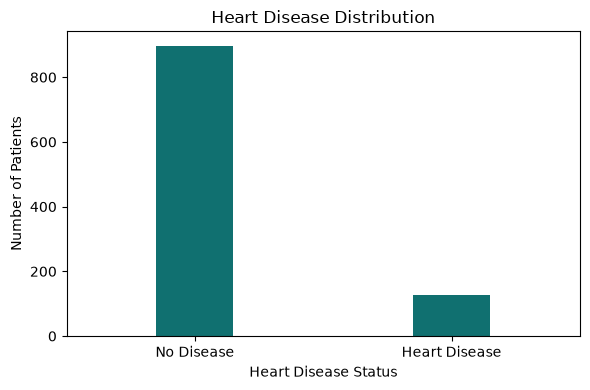

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="heart_disease",
    color="teal",
    width=0.3
)

plt.title("Heart Disease Distribution", fontsize=12)
plt.xlabel("Heart Disease Status")
plt.ylabel("Number of Patients")

plt.xticks([0, 1], ["No Disease", "Heart Disease"])

plt.tight_layout()
plt.show()

In [17]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 30, 40, 50, 60, 70, 120],
    labels=[
        "Under 30",
        "30–39",
        "40–49",
        "50–59",
        "60–69",
        "70+"
    ],
    right=False
)

In [18]:
age_rates = (
    df.groupby("age_group", observed=False)["heart_disease"]
    .mean() * 100
)

print(age_rates.round(2))

age_group
Under 30     0.00
30–39        6.78
40–49        8.64
50–59       12.11
60–69       19.00
70+         22.86
Name: heart_disease, dtype: float64


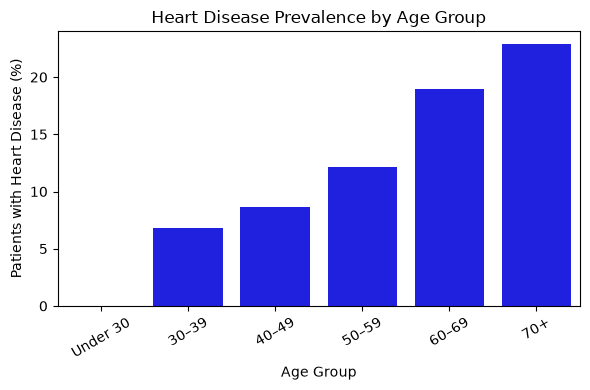

In [19]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=age_rates.index,
    y=age_rates.values,
    color="blue"
)

plt.title("Heart Disease Prevalence by Age Group", fontsize=12)
plt.xlabel("Age Group")
plt.ylabel("Patients with Heart Disease (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [20]:
print(age_rates.round(2))

age_group
Under 30     0.00
30–39        6.78
40–49        8.64
50–59       12.11
60–69       19.00
70+         22.86
Name: heart_disease, dtype: float64


In [21]:
bins = [0, 30, 40, 50, 60, 70, 120]

In [22]:
print(df["smoker"].value_counts(dropna=False))

smoker
No     738
Yes    287
Name: count, dtype: int64


In [23]:
smoking_rates = (
    df.groupby("smoker", dropna=False)["heart_disease"]
    .mean() * 100
)

print(smoking_rates.round(2))

smoker
No     11.52
Yes    14.98
Name: heart_disease, dtype: float64


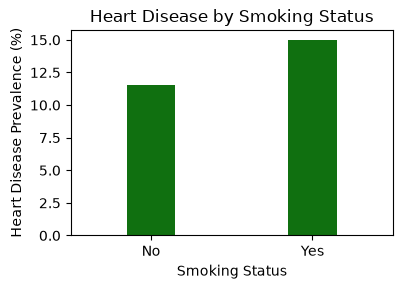

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(4, 3))

sns.barplot(
    data=df,
    x="smoker",
    y="heart_disease",
    estimator=lambda x: x.mean() * 100,
    errorbar=None,
    color="green",
     width=0.3
)

plt.title("Heart Disease by Smoking Status", fontsize=12)
plt.xlabel("Smoking Status")
plt.ylabel("Heart Disease Prevalence (%)")

plt.tight_layout()
plt.show()

In [25]:
# Calculate heart disease prevalence by sex
sex_rates = (
    df.groupby("sex")["heart_disease"]
    .mean() * 100
)

print(sex_rates.round(2))

sex
Female    10.49
Male      13.41
Name: heart_disease, dtype: float64


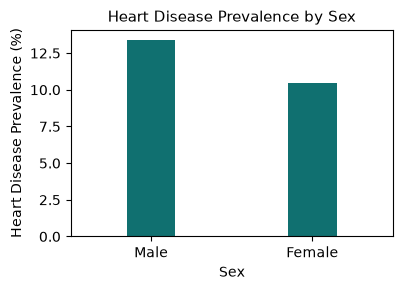

In [26]:
plt.figure(figsize=(4, 3))

sns.barplot(
    data=df,
    x="sex",
    y="heart_disease",
    estimator=lambda x: x.mean() * 100,
    errorbar=None,
    color="teal",
     width=0.3
)

plt.title("Heart Disease Prevalence by Sex", fontsize=11)
plt.xlabel("Sex")
plt.ylabel("Heart Disease Prevalence (%)")

plt.tight_layout()
plt.show()

In [27]:
# Calculate heart disease prevalence by chest pain type
chest_pain_rates = (
    df.groupby("chest_pain_type")["heart_disease"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(chest_pain_rates.round(2))

chest_pain_type
asymptomatic       19.68
typical angina      9.17
non-anginal         7.58
atypical angina     5.80
Name: heart_disease, dtype: float64


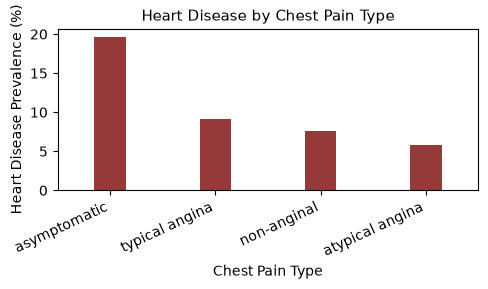

In [28]:
plt.figure(figsize=(5, 3))

sns.barplot(
    x=chest_pain_rates.index,
    y=chest_pain_rates.values,
    color="brown",
    width=0.3
)

plt.title("Heart Disease by Chest Pain Type", fontsize=11)
plt.xlabel("Chest Pain Type")
plt.ylabel("Heart Disease Prevalence (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [29]:
cholesterol_means = (
    df.groupby("heart_disease")["cholesterol"]
    .mean()
)

print(cholesterol_means)

heart_disease
0    233.098494
1    243.722689
Name: cholesterol, dtype: float64


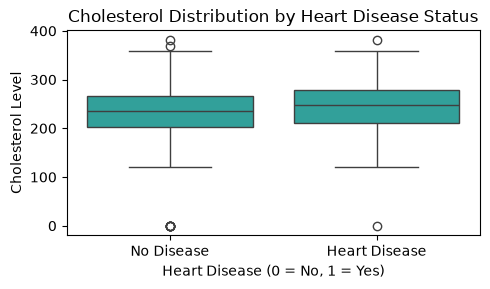

In [30]:
plt.figure(figsize=(5, 3))

sns.boxplot(
    data=df,
    x="heart_disease",
    y="cholesterol",
    color="lightseagreen"
)

plt.title("Cholesterol Distribution by Heart Disease Status")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Cholesterol Level")
plt.xticks([0, 1], ["No Disease", "Heart Disease"])
plt.tight_layout()
plt.show()

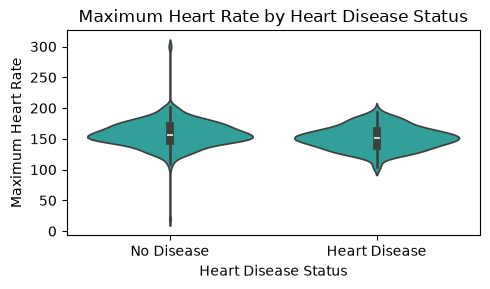

In [31]:
plt.figure(figsize=(5, 3))

sns.violinplot(
    data=df,
    x="heart_disease",
    y="max_heart_rate",
    color="lightseagreen",
    inner="box"
)

plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease Status")
plt.ylabel("Maximum Heart Rate")
plt.xticks([0, 1], ["No Disease", "Heart Disease"])
plt.tight_layout()
plt.show()

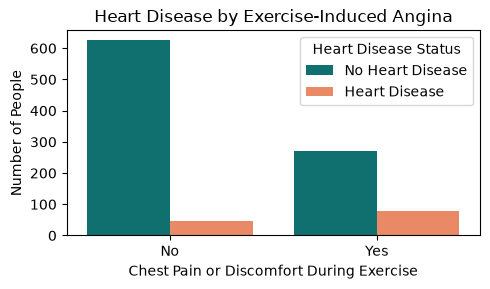

In [32]:
plt.figure(figsize=(5, 3))

sns.countplot(
    data=df,
    x="exercise_angina",
    hue="heart_disease",
    palette={0: "teal", 1: "coral"}
)

plt.title("Heart Disease by Exercise-Induced Angina")
plt.xlabel("Chest Pain or Discomfort During Exercise")
plt.ylabel("Number of People")

plt.xticks([0, 1], ["No", "Yes"])
plt.legend(
    title="Heart Disease Status",
    labels=["No Heart Disease", "Heart Disease"]
)

plt.tight_layout()
plt.show()

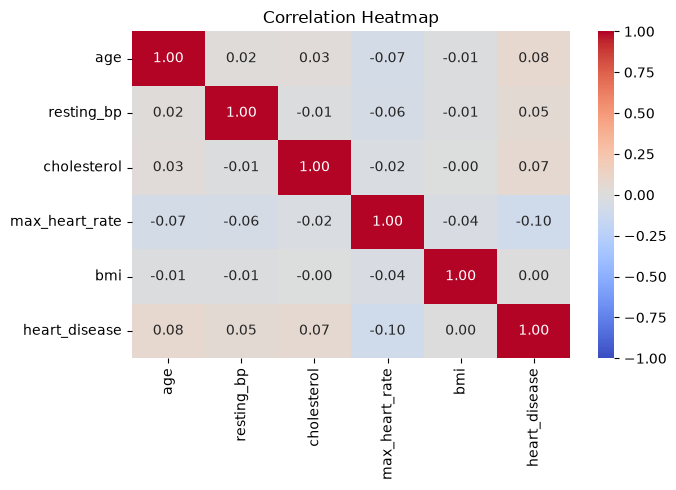

In [33]:
numeric_cols = [
    "age",
    "resting_bp",
    "cholesterol",
    "max_heart_rate",
    "bmi",
    "heart_disease"
]

plt.figure(figsize=(7, 5))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Final Conclusion

## 1. Overview

The purpose of this project was to clean and explore a heart disease dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn. The analysis involved identifying data quality issues, handling missing and inconsistent values, and creating visualisations to explore patterns between patient characteristics and heart disease status.

**The dataset used in this project is synthetic**, meaning it was created for practice and does not represent verified clinical records.

## 2. Key Findings

Several patterns were observed during exploratory data analysis:

- **Age:** Heart disease prevalence generally increased across the age groups, with the highest prevalence observed in the 70+ group.
- **Smoking status:** The heart disease group had a prevalence of approximately 15%, while the non-smoking group had a prevalence slightly above 10%.
- **Sex:** The prevalence was approximately 12.5% for males and 10% for females, a difference of 2.5 percentage points.
- **Chest pain type:** The asymptomatic group had the highest observed prevalence, at approximately 19.5%. Atypical angina had the lowest, at approximately 5%. Typical angina and non-anginal chest pain both had prevalence below 10%.
- **Cholesterol:** The box plot showed a higher median cholesterol level in the group with heart disease than in the group without heart disease.
- **Maximum heart rate:** The group without heart disease had a higher median maximum heart rate than the group with heart disease.

These findings describe patterns within the dataset. They do not demonstrate that any particular characteristic causes heart disease.

## 3. Data Quality and Cleaning

The cleaning process focused on improving data consistency and reliability by addressing missing values, inconsistent category labels, invalid numerical values, and duplicate records. These steps are important because data quality issues can affect statistical summaries and visualisations.

The effectiveness of the cleaning process depends on verifying that missing values and invalid records were handled appropriately and that the final dataset contains consistent, plausible values.

## 4. Limitations

This project has several limitations:

- The dataset is synthetic and cannot be assumed to reflect real-world patient populations.
- The observed patterns may have been influenced by the way the practice data was generated.
- The analysis is exploratory and does not establish causation.
- Differences between groups have not necessarily been tested for statistical significance.
- The results may be affected by missing data, class imbalance, and decisions made during data cleaning.
- The analysis considers selected variables individually and does not establish how multiple factors interact.

## 5. Conclusion

In conclusion, this project demonstrated how Python can be used to clean a dataset, assess data quality, summarise variables, and explore relationships through visualisations. The analysis identified patterns in the synthetic dataset involving age, smoking status, sex, chest pain type, cholesterol, and maximum heart rate.

The project strengthened practical skills in data preparation, grouping, calculating prevalence, and interpreting charts. Further work could include a correlation analysis, statistical significance testing, and—if the project scope requires it—a machine learning model evaluated using appropriate methods.

Overall, this project provides a foundation for understanding the data analysis workflow while emphasizing the importance of data quality, cautious interpretation, and awareness of dataset limitations.